In [1]:
from fastai.basics import *
from fastai.vision import models
from fastai.vision.all import *
from fastai.metrics import *
from fastai.data.all import *
from fastai.callback import *

# SemTorch
from semtorch import get_segmentation_learner
import os, random, torch,cv2
from pathlib import Path
torch.cuda.set_device(0)
%matplotlib inline
import numpy as np
import PIL
from PIL import Image, ImageOps
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
from sklearn import metrics

c:\Users\iisaragon\anaconda3\envs\torch\lib\site-packages\torch\nn\_reduction.py:42: UserWarning: size_average and reduce args will be deprecated, please use reduction='mean' instead.
  warnings.warn(warning.format(ret))


In [2]:
number_of_the_seed = 41
random.seed(number_of_the_seed)
set_seed(number_of_the_seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
# Introduce the path to the dataset 
path=Path('segmentation_dataset')

In [4]:
path.ls()

(#2) [Path('segmentation_dataset/test'),Path('segmentation_dataset/train')]

In [5]:
pathTrain=path/'train'
pathTrain.ls()

(#2) [Path('segmentation_dataset/train/images'),Path('segmentation_dataset/train/masks')]

In [6]:
pathTest=path/'test'
pathTest.ls()

(#2) [Path('segmentation_dataset/test/images'),Path('segmentation_dataset/test/masks')]

### Functions that will be helpful to get the files and masks. 

In [7]:
codes = np.array(['background','cancer'])

In [8]:
get_y_fn = lambda x: Path(str(x).replace("images","masks"))

def ParentSplitter(x):
    return Path(x).parent.parent.name=='test'

def get_files(path):
    return get_image_files(path/'train'/'images') + get_image_files(path/'test'/'images')

## Datablock and Data loaders

#### Data transformations

In [9]:
from albumentations import (Compose,HorizontalFlip,Rotate)

class SegmentationAlbumentationsTransform(ItemTransform):
    split_idx = 0
    def __init__(self, aug): 
        self.aug = aug
    def encodes(self, x):
        img,mask = x
        mask = PILMask.create(mask)
        return img, mask

transforms=Compose([HorizontalFlip(p=1),Rotate(p=1,limit=10)],p=1)
transformPipeline=SegmentationAlbumentationsTransform(transforms)

class TargetMaskConvertTransform(ItemTransform):
    def __init__(self): 
        pass
    def encodes(self, x):
        img,mask = x
        #Convert to array
        mask = np.array(mask)
        # Back to PILMask
        mask = PILMask.create(mask)
        return img, mask

#### Datablock

In [10]:
trainDB = DataBlock(blocks=(ImageBlock, MaskBlock(codes)),
                   get_items=get_files,
                   get_y=get_y_fn,
                   splitter=FuncSplitter(ParentSplitter),
                   item_tfms=[Resize((480,640)), TargetMaskConvertTransform(), transformPipeline],
                   batch_tfms=Normalize.from_stats(*imagenet_stats)
                  )

In [11]:
bs = 4
trainDLS = trainDB.dataloaders(path,bs=bs)

In [12]:
trainDB.summary(path)

Setting-up type transforms pipelines
Found 223 items
2 datasets of sizes 176,47
Setting up Pipeline: PILBase.create
Setting up Pipeline: <lambda> -> PILBase.create

Building one sample
  Pipeline: PILBase.create
    starting from
      segmentation_dataset\train\images\paciente0_15.png
    applying PILBase.create gives
      PILImage mode=RGB size=512x512
  Pipeline: <lambda> -> PILBase.create
    starting from
      segmentation_dataset\train\images\paciente0_15.png
    applying <lambda> gives
      segmentation_dataset\train\masks\paciente0_15.png
    applying PILBase.create gives
      PILMask mode=L size=512x512

Final sample: (PILImage mode=RGB size=512x512, PILMask mode=L size=512x512)


Found 223 items
2 datasets of sizes 176,47
Setting up Pipeline: PILBase.create
Setting up Pipeline: <lambda> -> PILBase.create
Setting up after_item: Pipeline: AddMaskCodes -> TargetMaskConvertTransform -> SegmentationAlbumentationsTransform -> Resize -- {'size': (640, 480), 'method': 'crop', 'pa

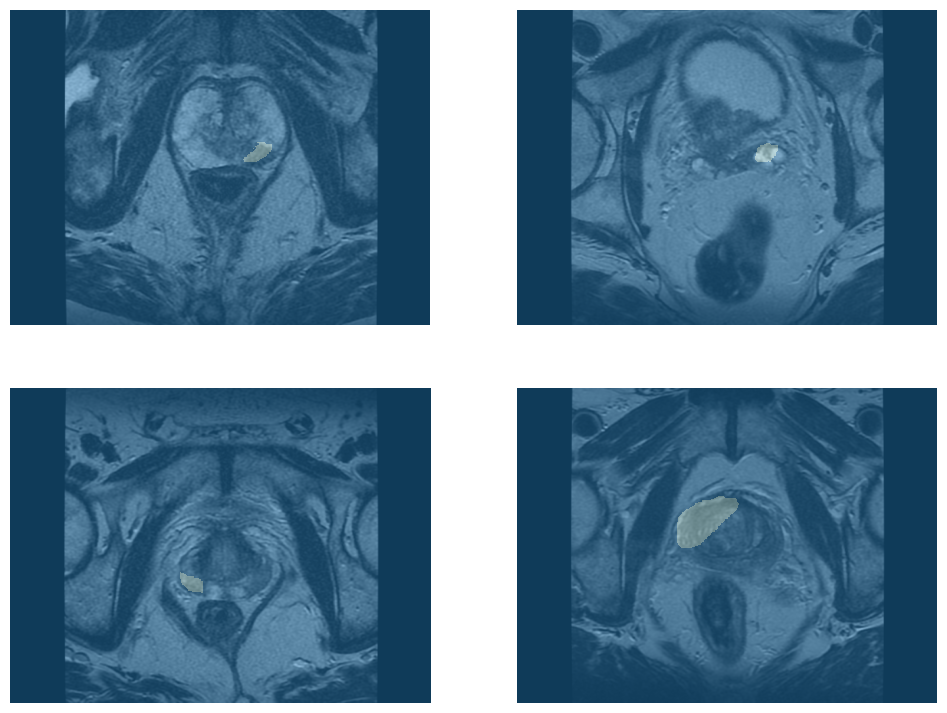

In [13]:
trainDLS.show_batch(vmin=0,vmax=1,figsize=(12, 9))

## Learner - HRNET

### Training

In [14]:
def cancer(input, target):
    target = target.squeeze(1)
    mask = target != 1
    return (input.argmax(dim=1)[mask]==target[mask]).float().mean()

In [15]:
from fastai.losses import DiceLoss
learn = get_segmentation_learner(dls=trainDLS, number_classes=2, segmentation_type="Semantic Segmentation",
                                 architecture_name="hrnet", backbone_name="hrnet_w30", loss_func=DiceLoss(),
                                 metrics=[cancer, Dice(), JaccardCoeff()],wd=1e-2,
                                 pretrained=True,normalize=True).to_fp16()

#### Freeze the backbone
 Decoder is trained
 

In [16]:
learn.freeze() # Freezing the backbone

##### Find the best learning rate to start training

Recorder

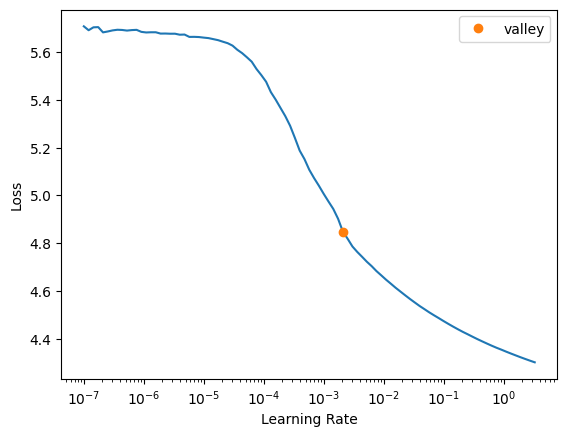

In [17]:
learn.lr_find() # find learning rate
learn.recorder

In [18]:
fname="hrnet-before-unfreeze-best"

callbacksFitBeforeUnfreeze = [
    ShowGraphCallback(),
    EarlyStoppingCallback(monitor='dice',comp=np.greater, patience=10),
    SaveModelCallback(monitor='dice',comp=np.greater,every_epoch=False,fname=fname), 
    ReduceLROnPlateau(monitor='dice',comp=np.greater,patience=4)  
]

epoch,train_loss,valid_loss,cancer,dice,jaccard_coeff,time
0,3.045043,3.512592,0.918929,0.170493,0.093191,00:20
1,3.202791,nan,1.000000,0.000000,0.000000,00:21
2,3.606310,3.988502,1.000000,0.000000,0.000000,00:20
3,3.689894,nan,1.000000,0.000000,0.000000,00:20
4,3.719990,nan,1.000000,0.000000,0.000000,00:20
5,3.631734,7.675884,0.000000,0.050836,0.026081,00:20
6,3.575294,nan,1.000000,0.000000,0.000000,00:20
7,3.464729,3.988502,1.000000,0.000000,0.000000,00:20
8,3.377825,3.988502,1.000000,0.000000,0.000000,00:20
9,3.383619,3.951407,0.986382,0.021642,0.010939,00:20


Better model found at epoch 0 with dice value: 0.17049290572013598.


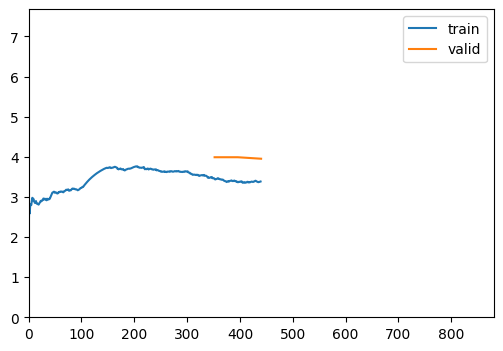

Epoch 4: reducing lr to 0.0009999510607378707
Epoch 8: reducing lr to 0.0008363318403435584
No improvement since epoch 0: early stopping


In [ ]:
learn.fit_one_cycle(20, slice(1e-3, 1e-2),cbs=callbacksFitBeforeUnfreeze)

In [19]:
learn.load(fname)

c:\Users\iisaragon\anaconda3\envs\torch\lib\site-packages\fastai\learner.py:59: UserWarning: Saved filed doesn't contain an optimizer state.
  elif with_opt: warn("Saved filed doesn't contain an optimizer state.")


##### Validation in the test set (valid loss, cancer, dice score, jaccard idx)

In [20]:
learn.validate()

(#4) [3.512592315673828,0.9189286828041077,0.17049290572013598,0.09319062290231016]

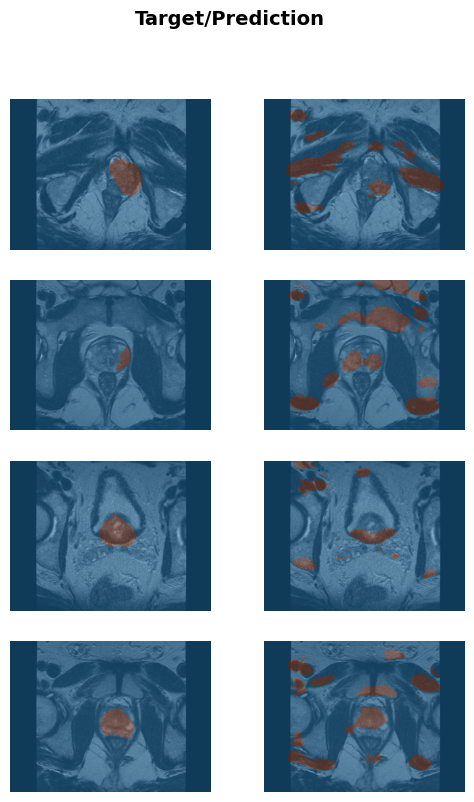

In [21]:
learn.show_results(figsize=(6,9))

#### Unfreeze the backbone
Encoder is trained

In [22]:
learn.unfreeze()

In [23]:
fname="hrnet-after-unfreeze-best"

callbacksFitAfterUnfreeze = [
    ShowGraphCallback(),
    EarlyStoppingCallback(monitor='dice',comp=np.greater, patience=7),
    SaveModelCallback(monitor='dice',comp=np.greater,every_epoch=False,fname=fname)  
]

epoch,train_loss,valid_loss,cancer,dice,jaccard_coeff,time
0,3.188758,2.764216,0.985601,0.323267,0.192796,00:21
1,2.767659,2.688053,0.994522,0.333196,0.199901,00:20
2,2.639296,2.668779,0.996577,0.346405,0.209486,00:20
3,2.554708,3.180058,0.998854,0.193253,0.106962,00:20
4,2.535130,3.502112,0.999711,0.106908,0.056472,00:20
5,2.536153,2.735929,0.995076,0.323294,0.192815,00:20
6,2.595814,3.815222,0.999904,0.027257,0.013817,00:20
7,2.556117,2.902159,0.989715,0.309012,0.182741,00:20
8,2.626853,3.635064,0.992684,0.081556,0.042511,00:20
9,2.785535,3.988502,1.000000,0.000000,0.000000,00:20


Better model found at epoch 0 with dice value: 0.32326728664954774.


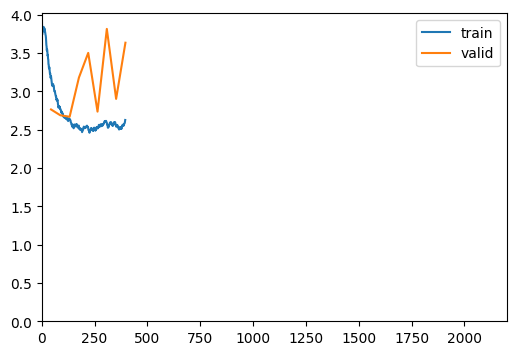

Better model found at epoch 1 with dice value: 0.3331962744457375.
Better model found at epoch 2 with dice value: 0.34640489823862575.
No improvement since epoch 2: early stopping


In [ ]:
learn.fit_one_cycle(50, slice(1e-5, 1e-3),cbs=callbacksFitAfterUnfreeze)

In [24]:
learn.load(fname)

c:\Users\iisaragon\anaconda3\envs\torch\lib\site-packages\fastai\learner.py:59: UserWarning: Saved filed doesn't contain an optimizer state.
  elif with_opt: warn("Saved filed doesn't contain an optimizer state.")


In [25]:
learn.validate()

(#4) [2.6687793731689453,0.9965771436691284,0.34640489823862575,0.20948592425657445]

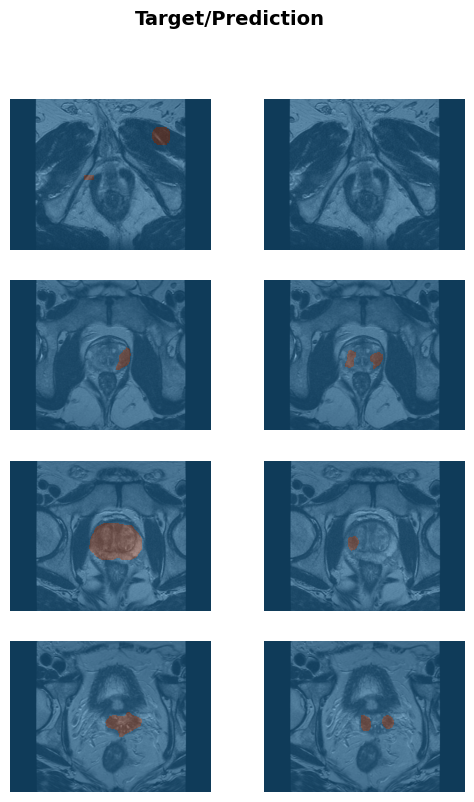

In [26]:
learn.show_results(figsize=(6,9))

### Saving the model

In [51]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
model=learn.model
model=model.cpu()
traced_cell=torch.jit.script(model)
#traced_cell.save("models/hrnet.pth")

### Load the model

In [68]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
model = torch.jit.load("models/hrnet.pth")
model = model.cpu()

## Predictions

In [38]:
import PIL
from PIL import Image, ImageOps
import torchvision.transforms as transforms
mean= Normalize.from_stats(*imagenet_stats).mean.flatten()
std= Normalize.from_stats(*imagenet_stats).std.flatten()
def transform_image(image):
    my_transforms = transforms.Compose([transforms.ToTensor(),
                                        transforms.Normalize(mean=mean, std=std)])
    image_aux = image
    return my_transforms(image_aux).unsqueeze(0).to(device)

In [39]:
def prediction(path, aux=model):
  img = PIL.Image.open(path).convert('RGB')
  image = transforms.Resize((480,480))(img)
  tensor = transform_image(image=image)
  aux.to(device)
  with torch.no_grad():
      outputs = aux(tensor)
  outputs = torch.argmax(outputs,1)
  mask = np.array(outputs.cpu())
  mask=np.reshape(mask,(480,480))
  return np.array(transforms.Resize(img.shape)(Image.fromarray(mask.astype('uint8'))))

In [70]:
path_save=Path('predictions_hrnet')
os.mkdir(path_save)

In [73]:
files=get_image_files(pathTest/'images')
for f in files:
    mask=prediction(str(f))
    cv2.imwrite(str(path_save/f.name), 255*mask)

### Show the predicted mask

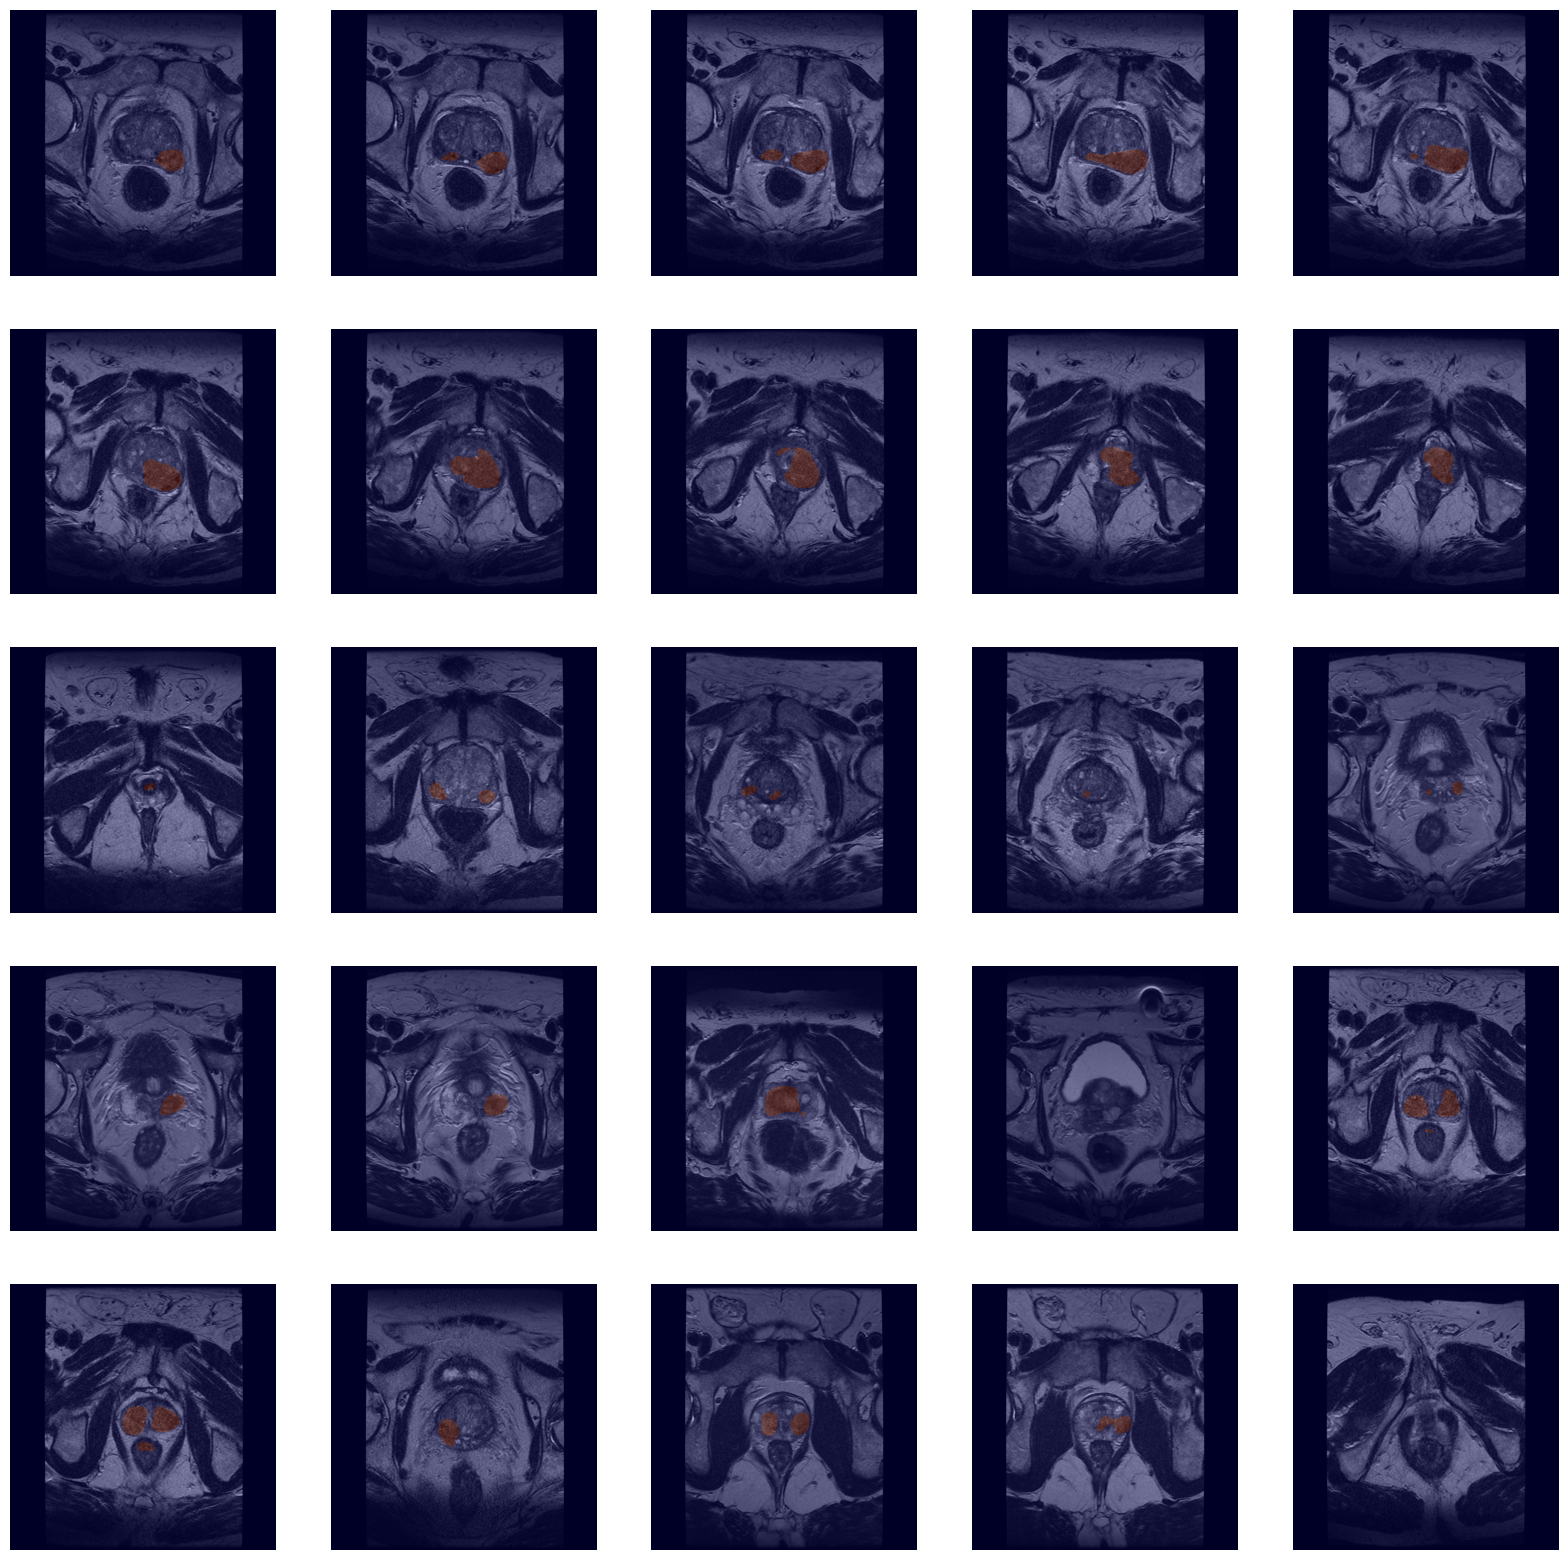

In [74]:
imgs=[]
for file in os.listdir(pathTest):
    img=cv2.imread(str(pathTest/file))
    mask=cv2.imread(str(path_save/file),0)
    mask=cv2.applyColorMap(mask, cv2.COLORMAP_JET)
    img=cv2.addWeighted(img,0.7,mask,0.3,0)
    imgs.append(img)

plt.figure(figsize=(20,20))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.imshow(cv2.cvtColor(imgs[i], cv2.COLOR_BGR2RGB))
    plt.axis('off')